# Typer AI – postęp prac po Proof of Concept

**Zajęcia: 22.11.2026** · poprzednia prezentacja (PoC): 8.11.2026

Typer AI to polskojęzyczny chatbot do analizy meczów Ekstraklasy: model statystyczny (Dixon-Coles) + kursy ok. 20 bukmacherów + LLM (Gemini) z narzędziami. Cel: trafność typów > 50% i dodatni ROI w teście na żywo.

**Plan:**
1. Zrealizowane prace od PoC
2. Demonstracja – metryki: walidacja walk-forward modelu (uruchamiana na żywo), symulacja reguł typów, stan testu na żywo
3. Use-case'y: narzędzia czatu, guardrails, rozmowa z LLM, aplikacja webowa
4. Napotkane problemy i sposoby ich rozwiązania
5. Kolejne kroki i priorytety

> Notebook tylko **czyta** bazę (`mode=ro`), więc można go uruchomić na kopii bazy (`data/typer.db`).

In [1]:
import os, sys, json, sqlite3, subprocess, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typerai import config, report
from typerai.betting import odds_math

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

conn = report.connect_ro()
print("Baza:", config.DB_PATH)

Baza: C:\Users\Tomek\Desktop\projekt krzywda\typer-ai\data\typer.db


## 1. Zrealizowane prace od PoC (8.11 → 22.11)

| Obszar | Co zrobiono | Dlaczego |
|---|---|---|
| **Test na żywo** | harmonogram typów działa automatycznie: etap 1 (typ wstępny, 9:00 i 18:00), etap 2 (potwierdzenie ok. 60 min przed meczem na świeżych kursach), rozliczenie (10:30 i 23:45) | typy muszą być zbierane bez udziału człowieka, z zapisem kursów do pomiaru CLV |
| **Analiza braku typów** | przez 13 dni harmonogram nie wydał ani jednego typu → analiza: z 70 ocenionych zdarzeń próg EV ≥ 3% zablokował 69 | założenie „najlepszy kurs spośród 20 bukmacherów daje przewagę” się nie sprawdziło |
| **Zmiana reguł** | oficjalny próg EV **3% → 1%** (na podstawie symulacji, sekcja 2.2); waga modelu bez zmian | ok. 22 typy na sezon zamiast 8 – próbka wystarczająca do oceny |
| **Strategia „cień”** | równoległe typy z łagodniejszymi regułami (EV ≥ 0%, p ≥ 45%, kurs 1,50–3,00), **tylko do pomiaru modelu** | większa próbka do oceny trafności i CLV w krótkim teście |
| **Niezawodność** | nadrabianie pominiętych terminów po wybudzeniu komputera; spójna kopia bazy w trakcie pracy (`python -m typerai.db --backup`); przeniesienie harmonogramu z laptopa na komputer stacjonarny | laptop usypiany → etap 1 wykonał się 1 raz zamiast ok. 26 |
| **Aplikacja webowa (Streamlit)** | strony **Czat** (z panelem „Jak powstała odpowiedź”), **Typy** (typy + „dlaczego jest albo nie ma typu”), **Wyniki** (test na żywo + walidacja) | interfejs dla użytkownika i do prezentacji zamiast terminala |
| **Organizacja** | dziennik decyzji (`docs/DZIENNIK.md`), zasady pracy dwóch osób na trzech komputerach (`CONTRIBUTING.md`) | wspólny kontekst dla zespołu i sesji AI |

In [2]:
# Historia zmian od PoC (git)
try:
    log = subprocess.run(["git", "log", "--since=2026-11-08", "--format=%ad  %s", "--date=short"],
                         cwd=ROOT, capture_output=True, text=True, encoding="utf-8").stdout
    print(log or "(brak gita)")
except FileNotFoundError:
    print("(git niedostępny)")

2026-11-21  Merge pull request #2 from Tomek586/feat/aplikacja-streamlit
2026-11-21  Merge pull request #1 from Tomek586/docs/harmonogram-komputer-domowy
2026-11-21  docs: log the web app and the progress notebook
2026-11-21  docs: add progress notebook for the post-PoC review
2026-11-21  feat: add Streamlit app with chat, picks and results pages
2026-11-21  docs: log scheduler start on the home computer
2026-11-21  feat: catch up missed scheduler runs and add shadow pick strategy
2026-11-21  docs: log scheduler removal from the laptop
2026-11-21  docs: add contributing guide, decision log and scheduler migration



In [3]:
# Stan bazy danych
tables = ["match", "match_stats", "lineup", "player", "odds_snapshot", "prediction", "pick", "job_run"]
pd.DataFrame([{"tabela": t, "wierszy": conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]} for t in tables])

,tabela,wierszy
0,match,4217
1,match_stats,3373
2,lineup,99250
3,player,2400
4,odds_snapshot,44736
5,prediction,15
6,pick,2
7,job_run,336


## 2. Demonstracja – metryki

### 2.1 Walidacja walk-forward modelu v1 (uruchamiana na żywo)

Nasz odpowiednik „treningu przez kilka epok”: model **Dixon-Coles** dopasowywany **co tydzień** wyłącznie na meczach sprzed danego tygodnia (tak jak w produkcji, bez wycieku informacji), przez dwa sezony walidacyjne (2 × 306 meczów). Porównujemy z rynkiem: kursy zamknięcia Pinnacle bez marży (metoda Shina).

Metryki dla 1X2 (mniej = lepiej): **log-loss**, **Brier**, **RPS**. Trwa ok. 1 minuty.

In [4]:
from evaluation import validate_v1 as v

raw = sqlite3.connect(f"file:{Path(config.DB_PATH).as_posix()}?mode=ro", uri=True)
W = config.MODEL["blend_w"]
runs = {}
for season in ["2023/24", "2024/25"]:
    t0 = time.perf_counter()
    history, target, odds = v.load(raw, season)
    results = {m[0]: v.result_index(m[3], m[4]) for m in target}
    market = {}
    for mid in results:
        q = odds.get((mid, "pinnacle")) or odds.get((mid, "market_avg"))
        if q and all(o in q for o in v.OUTCOMES):
            market[mid] = np.array(odds_math.shin([q[o] for o in v.OUTCOMES]))
    results = {k: r for k, r in results.items() if k in market}
    model = {k: p for k, p in v.walk_forward(history, target, config.MODEL["xi"]).items() if k in results}
    runs[season] = dict(results=results, market=market, model=model, odds=odds)
    print(f"{season}: {len(model)} meczów, czas {time.perf_counter() - t0:.0f} s")

rows = []
for season, r in runs.items():
    blend = {k: v.blend(r["model"][k], r["market"][k], W) for k in r["model"]}
    for name, probs in [("rynek (Pinnacle, Shin)", r["market"]), ("model v1 (Dixon-Coles)", r["model"]),
                        (f"mieszanka w={W:g}", blend)]:
        m = v.metrics({k: probs[k] for k in r["results"]}, r["results"])
        rows.append({"sezon": season, "prognoza": name, "log-loss": m["log_loss"], "Brier": m["brier"], "RPS": m["rps"], "n": m["n"]})
metrics = pd.DataFrame(rows)
metrics.style.format({"log-loss": "{:.4f}", "Brier": "{:.4f}", "RPS": "{:.4f}"}).hide(axis="index")

2023/24: 306 meczów, czas 21 s


2024/25: 306 meczów, czas 26 s


sezon,prognoza,log-loss,Brier,RPS,n
2023/24,"rynek (Pinnacle, Shin)",1.0613,0.6429,0.2152,306
2023/24,model v1 (Dixon-Coles),1.0627,0.6428,0.2155,306
2023/24,mieszanka w=0.15,1.0592,0.6415,0.2146,306
2024/25,"rynek (Pinnacle, Shin)",1.0204,0.6130,0.2126,306
2024/25,model v1 (Dixon-Coles),1.0414,0.6226,0.2181,306
2024/25,mieszanka w=0.15,1.0220,0.6137,0.2131,306


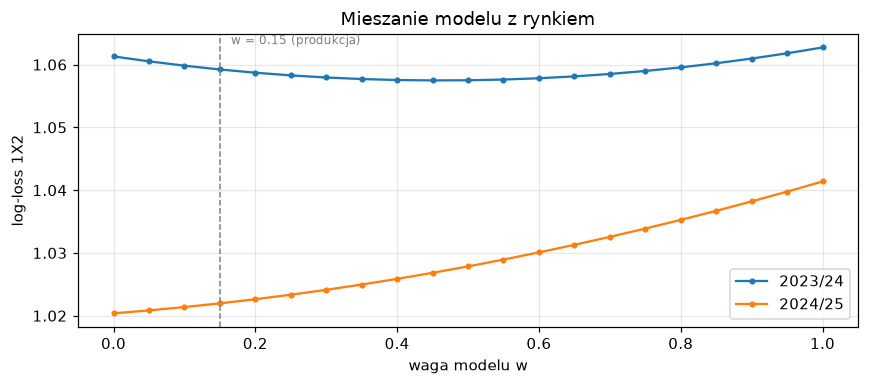

In [5]:
# Log-loss mieszanki w zależności od wagi modelu w (0 = sam rynek, 1 = sam model)
fig, ax = plt.subplots(figsize=(8, 3.6))
for season, r in runs.items():
    ws = np.round(np.arange(0, 1.01, 0.05), 2)
    ll = [v.metrics({k: v.blend(r["model"][k], r["market"][k], w) for k in r["model"]}, r["results"])["log_loss"] for w in ws]
    ax.plot(ws, ll, marker="o", ms=3, label=season)
ax.axvline(W, ls="--", c="gray", lw=1)
ax.text(W + 0.01, ax.get_ylim()[1], f" w = {W:g} (produkcja)", va="top", fontsize=8, color="gray")
ax.set_xlabel("waga modelu w"); ax.set_ylabel("log-loss 1X2"); ax.set_title("Mieszanie modelu z rynkiem")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Wniosek:** model oparty tylko na wynikach **nie pokonuje rynku** (w 2024/25 log-loss 1,041 vs 1,020). Mała waga modelu (w = 0,15) daje mieszankę na poziomie rynku. To uczciwy wynik badawczy: przewagi musi szukać **model v2** (siła składu, forma, motywacja, zmęczenie) – każda cecha zostanie tylko, jeśli poprawi ten sam backtest.

### 2.2 Symulacja reguł wyboru typów → decyzja o progu EV

Na tych samych prognozach (mieszanka w = 0,15) symulujemy reguły typu na **najlepszym kursie zamknięcia** z rynku 1X2. Stawka 1 j. na typ, jeden typ na mecz.

In [6]:
variants = {
    "stare reguły (EV ≥ 3%)": dict(w=W, ev_min=0.03),
    "nowe reguły (EV ≥ 1%)": dict(w=W, ev_min=0.01),
    "„cień” (EV ≥ 0%, p ≥ 45%, kurs ≤ 3,00)": dict(w=W, ev_min=0.0, p_min=0.45, o_max=3.0),
    "sam model, bez rynku (EV ≥ 1%)": dict(w=1.0, ev_min=0.01),
}
sim = []
for name, kw in variants.items():
    w = kw.pop("w"); n = wins = 0; profit = 0.0
    for season, r in runs.items():
        probs = {k: v.blend(r["model"][k], r["market"][k], w) for k in r["model"]}
        s = v.simulate_rules(probs, r["market"], r["results"], r["odds"], "market_max", **kw)
        if s["typy"]:
            n += s["typy"]; wins += round(s["trafnosc"] * s["typy"]); profit += s["roi"] * s["typy"]
    kw["w"] = w
    sim.append({"wariant": name, "typy / sezon": n / 2, "trafność": wins / n if n else None, "ROI": profit / n if n else None})
sim = pd.DataFrame(sim)
sim.style.format({"typy / sezon": "{:.1f}", "trafność": "{:.1%}", "ROI": "{:+.1%}"}).hide(axis="index")

wariant,typy / sezon,trafność,ROI
stare reguły (EV ≥ 3%),8.0,43.8%,-18.2%
nowe reguły (EV ≥ 1%),22.5,55.6%,-0.3%
"„cień” (EV ≥ 0%, p ≥ 45%, kurs ≤ 3,00)",70.5,47.5%,-8.1%
"sam model, bez rynku (EV ≥ 1%)",42.0,50.0%,-6.3%


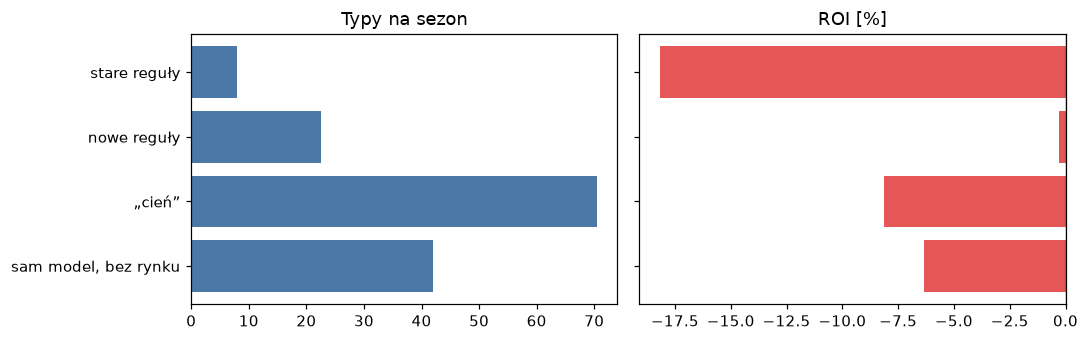

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = [s.split(" (")[0] for s in sim["wariant"]]
axes[0].barh(labels, sim["typy / sezon"], color="#4C78A8"); axes[0].set_title("Typy na sezon"); axes[0].invert_yaxis()
colors = ["#54A24B" if x > 0 else "#E45756" for x in sim["ROI"]]
axes[1].barh(labels, sim["ROI"] * 100, color=colors); axes[1].axvline(0, c="k", lw=.8)
axes[1].set_title("ROI [%]"); axes[1].invert_yaxis(); axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Decyzja (21.11):** oficjalny próg EV **3% → 1%**. Stare reguły dawały ok. 8 typów na sezon – za mało, żeby cokolwiek ocenić. Wagi modelu **nie zmieniamy** pod wynik ROI (to byłoby przeuczenie na małej próbce); waga wynika z log-loss. Próbki są małe – traktujemy to jako kierunek, nie dowód.

### 2.3 Test na żywo – czy system działa

Harmonogram działa od 8.11 (od 21.11 na komputerze stacjonarnym). Każde uruchomienie etapu zapisuje się w tabeli `job_run`.

In [8]:
jobs = pd.read_sql("SELECT job, status, started_at FROM job_run", conn)
summary = jobs.pivot_table(index="job", columns="status", values="started_at", aggfunc="count", fill_value=0)
summary["ostatnie uruchomienie (UTC)"] = jobs.groupby("job")["started_at"].max().str[:16]
summary

status,ok,ostatnie uruchomienie (UTC)
job,,
settle,10,2026-11-21T11:20
stage1,2,2026-11-21T11:20
stage2,324,2026-11-21T12:30


In [9]:
live = report.live_summary(conn)
print("Wszystkie typy w bazie:", live["wszystkie_typy"])
for name in ("oficjalna", "cień"):
    s = live[name]
    print(f"Strategia {name}: rozliczonych {s['typy']}, trafność {s['trafnosc'] or '–'}, ROI {s['roi'] or '–'}")
picks = pd.DataFrame(report.picks(conn))
picks[["termin", "mecz", "zdarzenie", "strategia", "status", "p_model", "ev", "kurs_etap1", "bukmacher"]] if len(picks) else "brak typów"

Wszystkie typy w bazie: 2
Strategia oficjalna: rozliczonych 0, trafność –, ROI –
Strategia cień: rozliczonych 0, trafność –, ROI –


,termin,mecz,zdarzenie,strategia,status,p_model,ev,kurs_etap1,bukmacher
0,22.11.2026 12:15,Raków Częstochowa – Widzew Łódź,wygrana gospodarza (1),cień,wstępny,0.497,0.030,2.07,unibet_nl
1,21.11.2026 17:30,Zagłębie Lubin – Górnik Zabrze,"poniżej 2,5 gola",cień,wstępny,0.544,0.007,1.85,unibet_se


**Dlaczego tak mało typów?** Poniżej najbliższe mecze (rynek 1X2) liczone tak samo jak w etapie 1: prawdopodobieństwo modelu, rynku i mieszanki, najlepszy kurs po odrzuceniu ofert odstających i EV. Widać, że **najlepszy kurs jest zwykle gorszy od uczciwej ceny Pinnacle** – EV > 1% przy p ≥ 52% zdarza się rzadko.

In [10]:
up = pd.DataFrame(report.upcoming(conn))
if len(up):
    show = up[["termin", "mecz", "zdarzenie", "p_model", "p_rynek", "p_mieszanka", "kurs", "ev", "spelnia_reguly"]]
    display(show.sort_values("ev", ascending=False).head(12).style.format(
        {"p_model": "{:.1%}", "p_rynek": "{:.1%}", "p_mieszanka": "{:.1%}", "ev": "{:+.1%}"}, na_rep="–").hide(axis="index"))
    print(f"Zdarzeń 1X2: {len(up)}, z EV > 0: {(up['ev'] > 0).sum()}, spełniających reguły oficjalne: {up['spelnia_reguly'].sum()}")
else:
    print("Brak meczów w najbliższych 7 dniach")

termin,mecz,zdarzenie,p_model,p_rynek,p_mieszanka,kurs,ev,spelnia_reguly
22.11.2026 12:15,Raków Częstochowa – Widzew Łódź,wygrana gospodarza (1),58.1%,48.2%,49.7%,2.070000,+3.0%,False
21.11.2026 17:30,Zagłębie Lubin – Górnik Zabrze,wygrana gospodarza (1),32.5%,17.3%,19.3%,5.200000,+0.3%,False
21.11.2026 14:45,Cracovia – Jagiellonia Białystok,wygrana gościa (2),37.5%,37.5%,37.5%,2.630000,-1.4%,False
22.11.2026 14:45,GKS Katowice – Lech Poznań,wygrana gospodarza (1),33.4%,31.2%,31.6%,3.100000,-2.2%,False
21.11.2026 20:15,Radomiak Radom – Wisła Kraków,wygrana gospodarza (1),32.9%,32.3%,32.4%,3.000000,-2.9%,False
21.11.2026 17:30,Zagłębie Lubin – Górnik Zabrze,remis (X),31.8%,24.1%,25.5%,3.800000,-3.1%,False
21.11.2026 20:15,Radomiak Radom – Wisła Kraków,wygrana gościa (2),41.6%,42.4%,42.3%,2.290000,-3.2%,False
22.11.2026 17:30,Wisła Płock – Legia Warszawa,remis (X),30.6%,27.1%,27.6%,3.500000,-3.4%,False
22.11.2026 17:30,Wisła Płock – Legia Warszawa,wygrana gościa (2),44.2%,42.2%,42.5%,2.270000,-3.4%,False
21.11.2026 14:45,Cracovia – Jagiellonia Białystok,wygrana gospodarza (1),35.8%,37.3%,37.1%,2.600000,-3.5%,False


Zdarzeń 1X2: 27, z EV > 0: 2, spełniających reguły oficjalne: 0


## 3. Use-case'y

### 3.1 Narzędzia czatu (function calling)

LLM nie liczy sam prawdopodobieństw ani EV – wywołuje narzędzia, które zwracają JSON. Poniżej te same narzędzia wywołane bezpośrednio.

**Use-case 1:** „Jakie mecze są w najbliższych dniach?” → `terminarz`

In [11]:
from typerai.chat import tools, cli, numbers

def show(result, limit=1200):
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text[:limit] + ("\n…" if len(text) > limit else ""))

show(tools.terminarz(dni=3))

{
 "mecze": [
  {
   "termin": "21.11 14:45",
   "gospodarz": "Cracovia",
   "gosc": "Jagiellonia Białystok"
  },
  {
   "termin": "21.11 17:30",
   "gospodarz": "Zagłębie Lubin",
   "gosc": "Górnik Zabrze"
  },
  {
   "termin": "21.11 20:15",
   "gospodarz": "Radomiak Radom",
   "gosc": "Wisła Kraków"
  },
  {
   "termin": "22.11 12:15",
   "gospodarz": "Raków Częstochowa",
   "gosc": "Widzew Łódź"
  },
  {
   "termin": "22.11 14:45",
   "gospodarz": "GKS Katowice",
   "gosc": "Lech Poznań"
  },
  {
   "termin": "22.11 17:30",
   "gospodarz": "Wisła Płock",
   "gosc": "Legia Warszawa"
  },
  {
   "termin": "23.11 19:00",
   "gospodarz": "Wieczysta Kraków",
   "gosc": "Motor Lublin"
  }
 ]
}


**Use-case 2:** „Co sądzisz o meczu X?” → `analiza_meczu` (model + rynek + kurs minimalny + trendy H2H i formy)

In [12]:
first = tools.terminarz(dni=7)
mecz = (first.get("mecze") or [{}])[0]
print("Mecz:", mecz)
gosp, gosc = (mecz.get("gospodarz"), mecz.get("gosc")) if mecz.get("gospodarz") else ("Raków", "Widzew")
a = tools.analiza_meczu(gospodarz=gosp, gosc=gosc)
print("\nOczekiwane gole modelu:", a.get("oczekiwane_gole_modelu"), "| typ:", a.get("typ", "brak"))
pd.DataFrame(a.get("rynki", []))

Mecz: {'termin': '21.11 14:45', 'gospodarz': 'Cracovia', 'gosc': 'Jagiellonia Białystok'}



Oczekiwane gole modelu: {'gospodarz': 1.46, 'gosc': 1.49} | typ: None


,zdarzenie,p,p_model,zrodlo_p,kurs_minimalny,najlepszy_kurs,ev,ocena
0,wygrana gospodarza,0.371,0.358,model + rynek (Pinnacle),2.72,2.60,-0.035,najlepszy kurs 2.6 (tipico_de) jest poniżej mi...
1,remis,0.254,0.267,model + rynek (Pinnacle),3.98,3.60,-0.086,najlepszy kurs 3.6 (onexbet) jest poniżej mini...
2,wygrana gościa,0.375,0.375,model + rynek (Pinnacle),2.69,2.63,-0.014,najlepszy kurs 2.63 (unibet_nl) jest poniżej m...
3,gospodarz lub remis,0.625,0.625,model + rynek (Pinnacle),1.62,NaN,NaN,brak naszego kursu – warto tylko przy kursie c...
4,remis lub gość,0.629,0.642,model + rynek (Pinnacle),1.61,NaN,NaN,brak naszego kursu – warto tylko przy kursie c...
5,bez remisu,0.746,0.733,model + rynek (Pinnacle),1.35,NaN,NaN,brak naszego kursu – warto tylko przy kursie c...
6,"powyżej 1,5 gola",0.805,0.805,tylko model – brak kursów rynku,1.26,NaN,NaN,brak naszego kursu – warto tylko przy kursie c...
7,"powyżej 2,5 gola",0.575,0.566,model + rynek (Pinnacle),1.76,1.63,-0.063,najlepszy kurs 1.63 (onexbet) jest poniżej min...
8,"poniżej 2,5 gola",0.425,0.434,model + rynek (Pinnacle),2.38,2.20,-0.065,najlepszy kurs 2.2 (tipico_de) jest poniżej mi...
9,"poniżej 3,5 gola",0.658,0.658,tylko model – brak kursów rynku,1.53,NaN,NaN,brak naszego kursu – warto tylko przy kursie c...


**Use-case 3:** „Jak gra Legia?” → `forma_druzyny`; **Use-case 4:** „Jaka jest marża przy kursach 2,10 / 3,40 / 3,60?” → `przelicz_kurs`

In [13]:
show(tools.forma_druzyny(druzyna="Legia", ostatnie=5), 700)
print()
show(tools.przelicz_kurs(kursy=[2.10, 3.40, 3.60]))

{
 "druzyna": "Legia Warszawa",
 "mecze": [
  {
   "data": "08.11 17:30",
   "rywal": "Raków Częstochowa",
   "dom": true,
   "wynik": "2:4",
   "rezultat": "P"
  },
  {
   "data": "30.10 20:30",
   "rywal": "Górnik Zabrze",
   "dom": false,
   "wynik": "0:0",
   "rezultat": "R"
  },
  {
   "data": "25.10 17:30",
   "rywal": "Lech Poznań",
   "dom": true,
   "wynik": "1:2",
   "rezultat": "P"
  },
  {
   "data": "17.10 20:15",
   "rywal": "Cracovia",
   "dom": false,
   "wynik": "1:1",
   "rezultat": "R"
  },
  {
   "data": "11.10 20:15",
   "rywal": "Wisła Kraków",
   "dom": true,
   "wynik": "2:0",
   "rezultat": "W"
  }
 ],
 "punkty": 5,
 "bramki": "6:7",
 "najlepsi_strzelcy_sezonu": [
  
…

{
 "marza": 0.0481,
 "bez_marzy_proporcjonalnie": [
  0.4543,
  0.2806,
  0.265
 ],
 "bez_marzy_shin": [
  0.4587,
  0.2787,
  0.2626
 ]
}


### 3.2 Guardrails (bezpieczeństwo odpowiedzi)

- **wejście:** sygnały problemowego grania → odpowiedź wsparcia, bez typów i bez wywołania LLM,
- **wyjście:** usuwanie obietnic wygranej („pewniak”), dopisanie informacji o ryzyku przy kursach i typach,
- **G5 – kontrola liczb:** każda liczba dziesiętna i procent w odpowiedzi musi występować w wynikach narzędzi; w PoC słabszy model zmyślił „60,1%” zamiast „64,9%”.

In [14]:
q = "Przegrałem dziś wszystko, muszę się odegrać – daj pewniaka"
print("Wejście :", q)
print("HARM    :", bool(cli.HARM.search(q)), "→", cli.SUPPORT[:90], "…\n")

out = cli.guard_output("To pewniak, kurs 2,07 na Raków.")
print("Wyjście :", out, "\n")

tool_result = [{"p": 0.649, "najlepszy_kurs": 2.07}]
for answer in ["Szansa gospodarza to 64,9% przy kursie 2,07.", "Szansa gospodarza to 60,1% przy kursie 2,15."]:
    print(f"G5: {answer!r:55} → liczby spoza narzędzi: {numbers.unverified(answer, tool_result)}")

Wejście : Przegrałem dziś wszystko, muszę się odegrać – daj pewniaka
HARM    : True → Widzę, że sytuacja może być trudna. Nie podam teraz typów – w takiej chwili najlepiej zrob …

Wyjście : To [usunięte], kurs 2,07 na Raków.
⚠️ To analiza statystyczna, nie gwarancja. Każdy zakład może przegrać. Gra od 18 lat. 

G5: 'Szansa gospodarza to 64,9% przy kursie 2,07.'          → liczby spoza narzędzi: []
G5: 'Szansa gospodarza to 60,1% przy kursie 2,15.'          → liczby spoza narzędzi: [60.1, 2.15]


### 3.3 Pełna rozmowa z LLM (Gemini)

Ten sam potok co w aplikacji: łańcuch modeli Gemini (przełączanie przy limicie 429, błędzie 5xx, niedostępności 404 lub po 30 s), narzędzia, kontrola liczb G5 i guardrails. Komórka zużywa 2–4 zapytania z darmowego limitu (ok. 20 dziennie na model), dlatego uruchamia się tylko przy `TYPERAI_RUN_LLM=1`.

In [15]:
RUN_LLM = os.getenv("TYPERAI_RUN_LLM") == "1"
if RUN_LLM and os.getenv("GEMINI_API_KEY"):
    from google import genai
    cli.ECHO = False
    session = cli.ChatSession(genai.Client(http_options=cli.HTTP_OPTIONS))
    question = f"Co sądzisz o meczu {gosp} – {gosc}?"
    t0 = time.perf_counter()
    answer = cli.guard_output(cli.answer_question(session, question))
    print(f"Pytanie: {question}\nModel: {session.model}, czas {time.perf_counter() - t0:.1f} s")
    for t in cli.TRACE:
        print("  🔁", t["przelaczenie"]) if "przelaczenie" in t else print(f"  🔧 {t['narzedzie']}({t['argumenty']})")
    print("Kontrola liczb:", cli.LAST_CHECK, "\n")
    print(answer)
else:
    print("Pominięto (ustaw TYPERAI_RUN_LLM=1 i GEMINI_API_KEY). Demo na żywo: aplikacja Streamlit, strona Czat.")

Pytanie: Co sądzisz o meczu Cracovia – Jagiellonia Białystok?
Model: gemini-3.5-flash-lite, czas 3.7 s
  🔧 analiza_meczu({'gospodarz': 'Cracovia', 'gosc': 'Jagiellonia Białystok'})
Kontrola liczb: {'spoza_narzedzi': [], 'poprawka': False, 'po_poprawce': []} 

Analiza meczu **Cracovia – Jagiellonia Białystok** (termin: 21.11 14:45):

### Oczekiwane gole modelu
* Gospodarz: 1.46
* Gość: 1.49

### Najciekawsze rynki i kursy
| Zdarzenie | Prawdopodobieństwo (p) | Najlepszy kurs | Kurs minimalny | EV |
|---|---|---|---|---|
| Wygrana gospodarza | 0.371 | 2.60 | 2.72 | -0.035 |
| Remis | 0.254 | 3.60 | 3.98 | -0.086 |
| Wygrana gościa | 0.375 | 2.63 | 2.69 | -0.014 |
| Powyżej 2,5 gola | 0.575 | 1.63 | 1.76 | -0.063 |
| Poniżej 2,5 gola | 0.425 | 2.20 | 2.38 | -0.065 |
| Gospodarz lub remis | 0.625 | – | 1.62 | – |

*Uwaga: Dla zdarzeń bez podanego najlepszego kursu w tabeli (np. „Gospodarz lub remis” z kursem minimalnym 1.62), zakład ma wartość tylko, jeśli Twój bukmacher daje co najmniej w

### 3.4 Aplikacja webowa (Streamlit) – nowa funkcjonalność

Uruchomienie: `.venv/Scripts/streamlit run typerai/apps/streamlit_app.py` → http://localhost:8501

| Strona | Zawartość |
|---|---|
| **Czat** | rozmowa z Typer AI, przykładowe pytania, panel **„Jak powstała odpowiedź”**: model, przełączenia modeli, wywołania narzędzi z wynikami, kontrola liczb G5, guardrails |
| **Typy** | typy oficjalne i „cień” (status, p, EV, kursy etapów) oraz **„dlaczego jest albo nie ma typu”** dla najbliższych meczów |
| **Wyniki** | test na żywo (trafność, ROI, CLV, skumulowany zysk) i walidacja modelu (log-loss, symulacja reguł) |

**Czat** – odpowiedź z panelem „Jak powstała odpowiedź” (zrzut sprzed zmiany kolejności modeli: widać przełączenie po błędzie 504 i wywołanie narzędzia) oraz guardrail wejścia:

![Czat](img/app_czat.jpg)

**Typy:**

![Typy](img/app_typy.jpg)

**Wyniki:**

![Wyniki](img/app_wyniki.jpg)

## 4. Napotkane problemy i sposoby ich rozwiązania

| Problem | Skutek | Rozwiązanie / plan |
|---|---|---|
| Harmonogram na **laptopie**, który jest usypiany | etap 1 wykonał się 1 raz zamiast ok. 26; typy przepadały | ✅ nadrabianie pominiętych terminów; ✅ przeniesienie na komputer stacjonarny; zostaje wyłączenie usypiania |
| Reguły zbyt ostre (EV ≥ 3% przy wadze rynku 85%) | 0 typów w 13 dni (69 z 70 zdarzeń zablokowanych przez EV) | ✅ EV 1% (symulacja); ✅ strategia „cień” do pomiaru |
| Model v1 **nie pokonuje rynku** | brak realnej przewagi, mało typów z wartością | model v2: cechy składu (99 tys. wpisów składów z 90minut.pl już w bazie), forma, motywacja – każda cecha przez backtest |
| Darmowe limity i przeciążenie Gemini | ok. 20 zapytań dziennie na model; 21.11 `3.5-flash` i większe modele zwracały 503/504 po 36–60 s → odpowiedź po ok. 68 s | ✅ łańcuch 6 modeli z przełączaniem; ✅ pomiar czasów i nowa kolejność (najpierw modele „lite”, 0,5–3 s), limit 30 s; plan: Groq/Llama jako drugi dostawca, cache odpowiedzi do ewaluacji |
| LLM zmyśla liczby | błędne prawdopodobieństwa w odpowiedzi | ✅ guardrail G5 z automatyczną poprawką; plan: zbiór testowy 70 pytań |
| Źródła danych z ochroną przed botami (STS, SofaScore, Flashscore) | brak xG, kartek i rożnych z kursami | tylko legalne źródła (football-data, The Odds API, 90minut.pl za zgodą redakcji); rynek kartek przez **kurs minimalny** |
| Brak konta Jev (TypeSafe AI) | część decyzyjna (bramka typów, routing) nieprzetestowana | plan B: ten sam interfejs na LLM |
| Przerwa reprezentacyjna i zbliżająca się przerwa zimowa | mało meczów do testu na żywo | CLV jako wskaźnik na małej próbce; raport łączny backtest + test na żywo |

## 5. Kolejne kroki i priorytety

| Priorytet | Zadanie | Kryterium ukończenia |
|---|---|---|
| **1** | test na żywo bez przerw: wyłączenie usypiania komputera, monitoring harmonogramu (strona „System”) | etapy 1 i 2 przed każdym meczem |
| **2** | **model v2**: siła składu z 90minut.pl, forma, H2H, derby, motywacja, zmęczenie | lepszy log-loss niż mieszanka v1 w walk-forward na obu sezonach |
| **3** | model kartek (sędzia, drużyny) z kursem minimalnym | backtest + wyniki w czacie |
| **4** | newsy: wykrywanie kontuzji i zawieszeń (Jev lub LLM), przewidywany skład | F1 na ręcznie oznaczonym zbiorze |
| **5** | RAG: regulaminy bukmacherów i newsy z cytowaniem źródeł; strony aplikacji „Mecz”, „Newsy”, „System” | odpowiedzi z cytatem; demo końcowe |
| **6** | ewaluacja NLP: intencje, guardrails, RAG, 70 pytań testowych | tabele wyników do raportu |

**Co już działa i będzie rozwijane:** zbieranie danych (4215 meczów, 43 tys. kursów, składy od 2015), model v1 z walidacją, dwuetapowy cykl typu z rozliczaniem i CLV, chatbot z narzędziami i guardrails, aplikacja webowa.